# Aula 03: detecção de áudio falso no ASVspoof 5

PCS5917 IA Adversarial, EP-USP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LuizZucchi/portfolio-pcs5917/blob/main/notebooks/aula-03-asvspoof.ipynb)

Classificação binária bonafide × spoof com o dataset ASVspoof 5 (versão do Kaggle
[`ulianazb/asvspoof-2024`](https://www.kaggle.com/datasets/ulianazb/asvspoof-2024)). O pipeline segue o estudo de caso de
Almeida & Hayashi (SBCM 2021): features de médio prazo do [pyAudioAnalysis](https://github.com/tyiannak/pyAudioAnalysis)
e um SVM. Além do SVM, comparo outros classificadores e faço validação cruzada por falante, ablação de grupos de features
e curva de aprendizado com amostras maiores.

O dataset completo tem 57 GB, então o notebook baixa só os metadados e os FLAC sorteados para o subconjunto balanceado,
e guarda tudo numa pasta do Google Drive. Rodar de novo reaproveita o que já está lá.

**Token do Kaggle:** se estiver nos *Secrets* do Colab, com acesso liberado para este notebook, o download usa ele:
`KAGGLE_API_TOKEN` (token novo, `KGAT_...`) ou o par `KAGGLE_USERNAME` + `KAGGLE_KEY` (token legado do `kaggle.json`).
Como o dataset é público, o download também funciona sem token.

## 1. Setup

In [12]:
!pip install -q pyAudioAnalysis eyed3 pydub imbalanced-learn plotly hmmlearn soundfile

In [13]:
import os, io, re, json, shutil, struct, zlib, warnings, time
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from pyAudioAnalysis import MidTermFeatures

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

try:
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/PCS5917/aula-03"
    IN_COLAB = True
except ImportError:
    BASE = os.environ.get("AULA03_DIR", os.path.abspath("aula-03-data"))  # rodando local
    IN_COLAB = False

META_DIR, AUDIO_DIR, FIG_DIR = f"{BASE}/metadata", f"{BASE}/audios", f"{BASE}/figs"
for d in (META_DIR, AUDIO_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

KAGGLE_DATASET = "ulianazb/asvspoof-2024"
SEED = 42
N_POOL = 2500  # por classe, treino (ataques A01-A08); usado na curva de aprendizado
N_MAIN = 1000  # por classe, subconjunto dos experimentos principais
N_TEST = 500   # por classe, teste no dev (ataques A09-A16, nunca vistos no treino)

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

print("pasta de trabalho:", BASE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
pasta de trabalho: /content/drive/MyDrive/PCS5917/aula-03


### Kaggle

A API do Kaggle limita a taxa de downloads: depois de algumas centenas de requisições ela responde 404 por alguns minutos,
inclusive para arquivos que existem (seria de esperar um 429). Baixando os FLAC um por um, 4800 dos 6000 downloads falharam
na primeira execução.

Agora faço uma única requisição ao Kaggle, que redireciona para o `archive.zip` do dataset inteiro (57 GB) no Google Cloud
Storage, e leio só os pedaços que interessam com HTTP Range. O diretório central no fim do arquivo
(34 MB, 324 mil entradas) diz onde começa cada arquivo e quantos bytes ele ocupa comprimido. `RemoteZip` lê esse diretório
(com as extensões ZIP64, porque o arquivo passa de 4 GB) e `read` busca o cabeçalho local e os dados de um arquivo e
descomprime com `zlib`. A URL assinada vale 72 h.

O token, se houver, vem dos Secrets do Colab e só é lido quando algo precisa ser baixado. `kaggle_get` grava o arquivo no
destino; se ele já existe no Drive, não faz nada.

In [14]:
KAGGLE_URL = f"https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}"
_session = _zip = None

def kaggle_session():
    global _session
    if _session is None:
        if IN_COLAB:
            for k in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
                try:
                    os.environ[k] = userdata.get(k)
                except Exception:
                    pass  # secret não cadastrado
        _session = requests.Session()
        if os.environ.get("KAGGLE_API_TOKEN"):
            _session.headers["Authorization"] = f"Bearer {os.environ['KAGGLE_API_TOKEN']}"
        elif os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"):
            _session.auth = (os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"])
        # sem credencial o download também funciona, porque o dataset é público
    return _session

def zip_url():
    # quando estoura o limite de requisições o Kaggle responde 404 por alguns minutos
    for _ in range(30):
        r = kaggle_session().get(KAGGLE_URL, allow_redirects=False, timeout=60)
        if r.is_redirect:
            return r.headers["Location"]
        print(f"Kaggle respondeu {r.status_code}, tentando de novo em 60 s")
        time.sleep(60)
    r.raise_for_status()

def http_range(url, a, b, tries=5):  # bytes a até b-1
    for i in range(tries):
        try:
            r = requests.get(url, headers={"Range": f"bytes={a}-{b - 1}"}, timeout=120)
            r.raise_for_status()
            if len(r.content) == b - a:
                return r.content
            err = IOError(f"vieram {len(r.content)} de {b - a} bytes")
        except Exception as e:
            err = e
        time.sleep(2 ** i)
    raise err

class RemoteZip:
    def __init__(self, url):
        self.url = url
        r = requests.get(url, headers={"Range": "bytes=0-0"}, timeout=60)
        size = int(r.headers["Content-Range"].split("/")[1])
        # fim do arquivo: registro ZIP64 (56 bytes) + localizador ZIP64 (20) + EOCD (22)
        tail = http_range(url, size - 98, size)
        assert tail[-22:-18] == b"PK\x05\x06" and tail[-42:-38] == b"PK\x06\x07", "ZIP64 esperado"
        z64 = struct.unpack("<Q", tail[-34:-26])[0]
        rec = http_range(url, z64, z64 + 56)
        n, cd_size, cd_off = struct.unpack("<QQQ", rec[32:56])
        cd = http_range(url, cd_off, cd_off + cd_size)
        self.index, p = {}, 0
        while p < len(cd):
            method, = struct.unpack("<H", cd[p + 10:p + 12])
            csize, usize, nl, el, cl = struct.unpack("<IIHHH", cd[p + 20:p + 34])
            off, = struct.unpack("<I", cd[p + 42:p + 46])
            name = cd[p + 46:p + 46 + nl].decode()
            extra, q = cd[p + 46 + nl:p + 46 + nl + el], 0
            while q < len(extra):  # campo ZIP64 (id 1) com os valores que não couberam em 32 bits
                hid, hl = struct.unpack("<HH", extra[q:q + 4])
                if hid == 1:
                    vals = iter(struct.unpack(f"<{hl // 8}Q", extra[q + 4:q + 4 + hl // 8 * 8]))
                    if usize == 0xFFFFFFFF: usize = next(vals)
                    if csize == 0xFFFFFFFF: csize = next(vals)
                    if off == 0xFFFFFFFF: off = next(vals)
                q += 4 + hl
            self.index[name] = (off, csize, method)
            p += 46 + nl + el + cl
        assert len(self.index) == n

    def read(self, name):
        off, csize, method = self.index[name]
        b = http_range(self.url, off, off + 30 + len(name) + 256 + csize)  # folga para o extra do cabeçalho local
        nl, el = struct.unpack("<HH", b[26:30])
        data = b[30 + nl + el:30 + nl + el + csize]
        return zlib.decompress(data, -15) if method == 8 else data

def kaggle_zip():
    global _zip
    if _zip is None:
        _zip = RemoteZip(zip_url())
    return _zip

def kaggle_get(remote, dest):
    if os.path.exists(dest):
        return dest
    data = kaggle_zip().read(remote)
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    with open(dest + ".part", "wb") as f:
        f.write(data)
    os.replace(dest + ".part", dest)
    return dest

## 2. Metadados

O Kaggle traz dois arquivos de protocolo, um do treino (`T_*`) e outro do dev (`D_*`). Esta versão (julho de 2024) tem 6
colunas, `SPEAKER_ID FLAC_FILE_NAME GENDER - ATTACK KEY`; a versão final do ASVspoof 5 no Zenodo tem 10, com codecs. O parser
procura cada campo pelo padrão (id do arquivo, `A..`, `bonafide`/`spoof`) em vez de pela posição, então serve para as duas.

In [15]:
META_FILES = {"train": "ASVspoof5.train.metadata.txt", "dev": "ASVspoof5.dev.metadata.txt"}
for name in META_FILES.values():
    kaggle_get(name, f"{META_DIR}/{name}")

FILE_RE = re.compile(r"^[TD]_\d{10}$")
ATTACK_RE = re.compile(r"^(A\d{2}|bonafide)$")

def parse_meta(path, split):
    rows = []
    with open(path) as f:
        for line in f:
            tok = line.split()
            if not tok:
                continue
            key = [t for t in tok if t in ("bonafide", "spoof")][-1]
            rows.append(dict(
                speaker=tok[0],
                file_id=next(t for t in tok if FILE_RE.match(t)),
                gender=next((t for t in tok if t in ("F", "M")), None),
                attack=next(t for t in tok if ATTACK_RE.match(t)),
                label=key,
                split=split,
            ))
    return pd.DataFrame(rows)

for name in META_FILES.values():
    with open(f"{META_DIR}/{name}") as f:
        print(name, "->", [next(f).strip() for _ in range(2)])

meta = pd.concat([parse_meta(f"{META_DIR}/{n}", s) for s, n in META_FILES.items()], ignore_index=True)
meta.groupby(["split", "label"]).size().unstack()

ASVspoof5.train.metadata.txt -> ['T_4850 T_0000000000 F - A05 spoof', 'T_0858 T_0000000001 M - A07 spoof']
ASVspoof5.dev.metadata.txt -> ['D_0062 D_0000000001 F - A11 spoof', 'D_0755 D_0000000022 F - A16 spoof']


label,bonafide,spoof
split,,
dev,31334,109616
train,18797,163560


In [16]:
meta.groupby(["split", "attack"]).size().unstack(0).fillna(0).astype(int)

split,dev,train
attack,,
A01,0,20445
A02,0,20445
A03,0,20445
A04,0,20445
A05,0,20445
A06,0,20445
A07,0,20445
A08,0,20445
A09,13702,0


O dataset original é bem desbalanceado (cerca de 9 spoof para cada bonafide no treino), por isso o subconjunto balanceado.

## 3. Subconjunto balanceado

- **Treino** (metadados de treino, ataques A01 a A08): `N_POOL` bonafide e `N_POOL` spoof, com o spoof estratificado por ataque
  (mesmo número de amostras de cada um). Os experimentos principais usam `N_MAIN` por classe, tirados desse pool do mesmo jeito.
- **Teste** (metadados do dev, ataques A09 a A16): `N_TEST` por classe. Como os ataques do dev são diferentes dos do treino,
  esse teste mede se o detector generaliza para sistemas de síntese que nunca viu. Na prática é o caso que mais importa,
  porque um atacante não precisa usar um sistema que estava no treino.

O `subset.csv` fica salvo no Drive; se já existir, é reaproveitado, para o sorteio não mudar entre execuções.

In [17]:
def sample_balanced(df, n, seed=SEED):
    # se faltar algum arquivo, pega o que houver em vez de quebrar
    bona = df[df.label == "bonafide"]
    bona = bona.sample(min(n, len(bona)), random_state=seed)
    spoof = df[df.label == "spoof"]
    attacks = sorted(spoof.attack.unique())
    per = np.full(len(attacks), n // len(attacks))
    per[: n % len(attacks)] += 1
    sp = pd.concat([spoof[spoof.attack == a].pipe(lambda d: d.sample(min(k, len(d)), random_state=seed))
                    for a, k in zip(attacks, per)])
    return pd.concat([bona, sp])

SUBSET_CSV = f"{BASE}/subset.csv"
if os.path.exists(SUBSET_CSV):
    subset = pd.read_csv(SUBSET_CSV)
else:
    subset = pd.concat([
        sample_balanced(meta[meta.split == "train"], N_POOL).assign(part="train"),
        sample_balanced(meta[meta.split == "dev"], N_TEST).assign(part="test"),
    ], ignore_index=True)
    subset["path"] = "audios/" + subset.part + "/" + subset.label + "/" + subset.file_id + ".flac"
    subset.to_csv(SUBSET_CSV, index=False)

subset.groupby(["part", "label"]).size().unstack()

label,bonafide,spoof
part,,
test,500,500
train,2500,2500


### Download dos áudios

No Kaggle os arquivos ficam em `flac_T/flac_T/T_xxxxxxxxxx.flac` (treino) e `flac_D/flac_D/D_xxxxxxxxxx.flac` (dev). O download
é em paralelo, direto para o Drive, organizado em `audios/{train,test}/{bonafide,spoof}/`. Lendo do ZIP remoto, os 6000
levam alguns minutos; se a sessão cair, rodar a célula de novo só baixa o que falta.

In [18]:
def remote_path(file_id):
    p = file_id[0]  # T ou D
    return f"flac_{p}/flac_{p}/{file_id}.flac"

def fetch(row, tries=3):
    for i in range(tries):
        try:
            return kaggle_get(remote_path(row.file_id), f"{BASE}/{row.path}")
        except Exception as e:
            err = e
            time.sleep(2 ** i)
    return err

failed = []
todo = subset[~subset.path.map(lambda p: os.path.exists(f"{BASE}/{p}"))]
print(f"{len(subset) - len(todo)} já no Drive, {len(todo)} para baixar")
with ThreadPoolExecutor(16) as ex:
    futs = {ex.submit(fetch, r): r.file_id for r in todo.itertuples()}
    for fut in tqdm(as_completed(futs), total=len(futs)):
        if isinstance(fut.result(), Exception):
            failed.append((futs[fut], fut.result()))
print("falhas:", len(failed), failed[:5])

1200 já no Drive, 4800 para baixar


  0%|          | 0/4800 [00:00<?, ?it/s]

falhas: 0 []


## 4. Extração de features com pyAudioAnalysis

Para cada áudio, `MidTermFeatures.mid_feature_extraction` calcula 34 features de curto prazo (janela de 50 ms, passo de 25 ms):
ZCR, energia, entropia de energia, centróide, espalhamento, entropia, fluxo e rolloff espectrais, 13 MFCCs e 13 de chroma,
mais os deltas de cada uma. Em janelas de médio prazo de 1 s ele tira a média e o desvio padrão, e no fim tiro a média ao longo
do áudio, que é o mesmo que o `directory_feature_extraction` faz. São 136 features por arquivo.

O pyAudioAnalysis não lê FLAC (`read_audio_file` só aceita wav/aif/mp3/ogg), então leio com `soundfile` em `int16`, que é a
escala que a biblioteca espera (ela divide o sinal por 2¹⁵).

Junto, guardo quatro medidas do sinal que ficam fora do classificador principal: duração, fração de silêncio e silêncio no
início e no fim. Elas servem para checar um atalho conhecido no ASVspoof: em versões anteriores do desafio, só a duração do
silêncio já separava bonafide de spoof (Müller et al., 2021).

In [19]:
import io

MT_WIN, MT_STEP, ST_WIN, ST_STEP = 1.0, 1.0, 0.050, 0.025

def load(path, tries=4):
    # o Drive montado às vezes falha numa leitura isolada; ler os bytes de novo resolve
    for i in range(tries):
        try:
            with open(path, "rb") as f:
                return sf.read(io.BytesIO(f.read()), dtype="int16")
        except Exception as e:
            err = e
            time.sleep(1 + i)
    raise err

def extract(path):
    x, fs = load(path)
    if x.ndim > 1:
        x = x.mean(axis=1).astype(np.int16)
    mf, _, names = MidTermFeatures.mid_feature_extraction(
        x, fs, round(MT_WIN * fs), round(MT_STEP * fs), round(ST_WIN * fs), round(ST_STEP * fs))
    feats = dict(zip([n.replace(" ", "_") for n in names], mf.mean(axis=1)))

    frame = round(0.025 * fs)
    n = len(x) // frame
    rms = np.sqrt((x[: n * frame].astype(float).reshape(n, frame) ** 2).mean(axis=1)) + 1e-9
    active = 20 * np.log10(rms / rms.max()) > -40  # quadros a menos de 40 dB do pico
    idx = np.flatnonzero(active)
    feats.update(duration=len(x) / fs, silence_ratio=1 - active.mean(),
                 lead_sil=idx[0] * frame / fs, trail_sil=(n - 1 - idx[-1]) * frame / fs)
    return feats

def extract_row(file_id, path):
    try:
        return {"file_id": file_id, **extract(path)}
    except Exception as e:
        return {"file_id": file_id, "erro": repr(e)}

# antes de extrair, tenta de novo o download do que ficou faltando
missing = subset[~subset.path.map(lambda p: os.path.exists(f"{BASE}/{p}"))]
if len(missing):
    print(f"{len(missing)} áudios faltando, baixando de novo")
    for r in tqdm(missing.itertuples(), total=len(missing)):
        fetch(r)

# Ler 6000 arquivos pequenos direto do Drive leva horas (cerca de 1 s por arquivo). Copio para o disco local
# do Colab com várias threads e extraio de lá. Também guardo um audios.tar no Drive: nas próximas sessões,
# copiar um arquivo grande é muito mais rápido que copiar milhares de pequenos.
LOCAL = "/content/aula-03" if IN_COLAB else BASE
TAR = f"{BASE}/audios.tar"

def to_local(p):
    dst = f"{LOCAL}/{p}"
    if not os.path.exists(dst):
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy(f"{BASE}/{p}", dst)

if IN_COLAB:
    if os.path.exists(TAR) and not os.path.exists(f"{LOCAL}/audios"):
        print("extraindo audios.tar do Drive")
        shutil.unpack_archive(TAR, LOCAL)
    need = [p for p in subset.path if not os.path.exists(f"{LOCAL}/{p}")]
    if need:
        with ThreadPoolExecutor(32) as ex:
            list(tqdm(ex.map(to_local, need), total=len(need), desc="Drive -> disco local"))
        shutil.make_archive(TAR[:-4], "tar", LOCAL, "audios")

FEATS_CSV = f"{BASE}/features.csv"
feats = pd.read_csv(FEATS_CSV) if os.path.exists(FEATS_CSV) else pd.DataFrame(columns=["file_id"])
todo = subset[~subset.file_id.isin(feats.file_id)]
print(f"{len(feats)} já extraídos, {len(todo)} para extrair")
if len(todo):
    rows = Parallel(n_jobs=-1)(delayed(extract_row)(r.file_id, f"{LOCAL}/{r.path}")
                               for r in tqdm(todo.itertuples(), total=len(todo)))
    # arquivo que não abre pode ter vindo truncado: apaga, baixa de novo e tenta mais uma vez
    bad = todo[todo.file_id.isin([r["file_id"] for r in rows if "erro" in r])]
    retry = {}
    for r in bad.itertuples():
        for root in {BASE, LOCAL}:
            if os.path.exists(f"{root}/{r.path}"):
                os.remove(f"{root}/{r.path}")
        fetch(r)
        to_local(r.path)
        retry[r.file_id] = extract_row(r.file_id, f"{LOCAL}/{r.path}")
    rows = [retry.get(r["file_id"], r) for r in rows]
    errors = [r for r in rows if "erro" in r]
    print("falhas na extração:", len(errors), errors[:3])
    feats = pd.concat([feats, pd.DataFrame([r for r in rows if "erro" not in r])], ignore_index=True)
    feats.to_csv(FEATS_CSV, index=False)  # só os que deram certo; rodar de novo tenta o resto

SIGNAL_COLS = ["duration", "silence_ratio", "lead_sil", "trail_sil"]
FEAT_COLS = [c for c in feats.columns if c not in ["file_id"] + SIGNAL_COLS]
data = subset.merge(feats, on="file_id")
data["y"] = (data.label == "spoof").astype(int)  # spoof é a classe positiva
print(data.shape, len(FEAT_COLS), "features")
data.groupby(["part", "label"]).size().unstack()

Drive -> disco local:   0%|          | 0/6000 [00:00<?, ?it/s]

0 já extraídos, 6000 para extrair


  0%|          | 0/6000 [00:00<?, ?it/s]

falhas na extração: 0 []
(6000, 149) 136 features


label,bonafide,spoof
part,,
test,500,500
train,2500,2500


In [20]:
pool = data[data.part == "train"].reset_index(drop=True)
train = sample_balanced(pool, N_MAIN).reset_index(drop=True)
test = data[data.part == "test"].reset_index(drop=True)

X_tr, y_tr, g_tr = train[FEAT_COLS].values, train.y.values, train.speaker.values
X_te, y_te = test[FEAT_COLS].values, test.y.values
print("treino:", train.groupby("label").size().to_dict(), "| teste:", test.groupby("label").size().to_dict())
print("falantes no treino:", train.speaker.nunique())

treino: {'bonafide': 1000, 'spoof': 1000} | teste: {'bonafide': 500, 'spoof': 500}
falantes no treino: 395


## 5. Análise exploratória

### Duração e silêncio

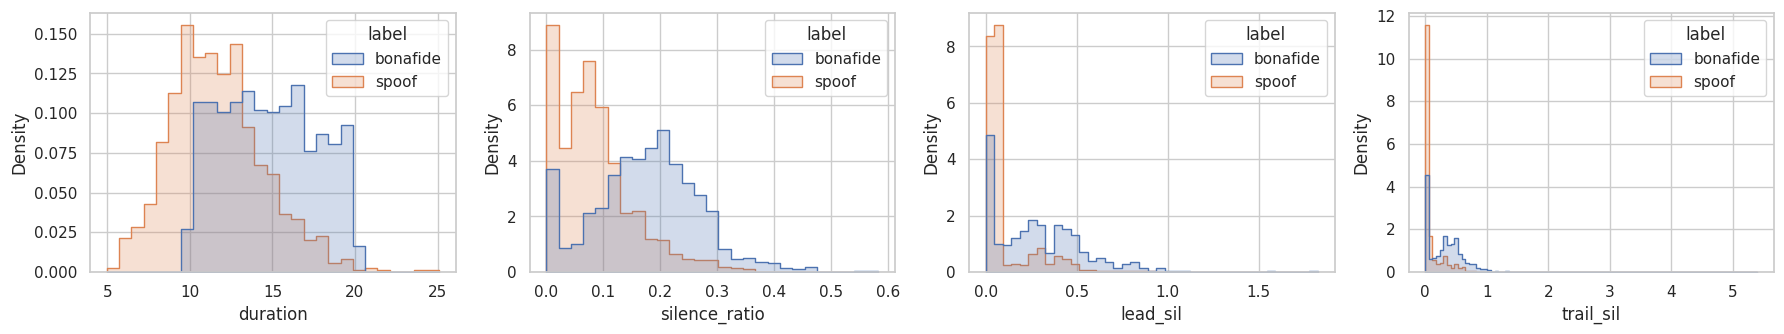

,duration,silence_ratio,lead_sil,trail_sil
label,,,,
bonafide,14.675,0.180,0.275,0.325
spoof,11.392,0.074,0.050,0.025


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, c in zip(axes, SIGNAL_COLS):
    sns.histplot(data=train, x=c, hue="label", stat="density", common_norm=False, element="step", ax=ax)
plt.tight_layout(); savefig("eda-silencio"); plt.show()

train.groupby("label")[SIGNAL_COLS].median().round(3)

Para medir o quanto essas medidas sozinhas separam as classes, treino uma regressão logística só com elas, na mesma validação
cruzada por falante usada mais adiante. Se a AUC passar muito de 0,5, o classificador pode estar aprendendo silêncio em vez de voz.

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
shortcut = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
auc_sil = cross_val_score(shortcut, train[SIGNAL_COLS], y_tr, groups=g_tr, cv=CV, scoring="roc_auc")
shortcut.fit(train[SIGNAL_COLS], y_tr)
from sklearn.metrics import roc_auc_score
print(f"AUC só com duração/silêncio: CV {auc_sil.mean():.3f} ± {auc_sil.std():.3f} | "
      f"teste {roc_auc_score(y_te, shortcut.decision_function(test[SIGNAL_COLS])):.3f}")

AUC só com duração/silêncio: CV 0.866 ± 0.025 | teste 0.620


### Quais features separam as classes

Duas medidas por feature, calculadas no treino: a informação mútua com o rótulo e o d de Cohen (diferença das médias
dividida pelo desvio padrão combinado; o sinal diz se a feature é maior no spoof ou no bonafide).

In [23]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_tr, y_tr, random_state=SEED)
a, b = train.loc[train.y == 1, FEAT_COLS], train.loc[train.y == 0, FEAT_COLS]
cohen_d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
rank = pd.DataFrame({"mi": mi, "cohen_d": cohen_d.values}, index=FEAT_COLS).sort_values("mi", ascending=False)
rank.head(15).round(3)

,mi,cohen_d
delta_mfcc_9_std,0.229,-1.485
delta_mfcc_10_std,0.215,-1.398
mfcc_1_mean,0.209,1.312
mfcc_10_std,0.180,-1.161
delta_mfcc_8_std,0.166,-1.251
mfcc_9_std,0.165,-1.216
delta_mfcc_7_std,0.160,-1.209
mfcc_8_std,0.153,-1.139
delta_mfcc_11_std,0.150,-1.173
delta_mfcc_12_std,0.142,-1.007


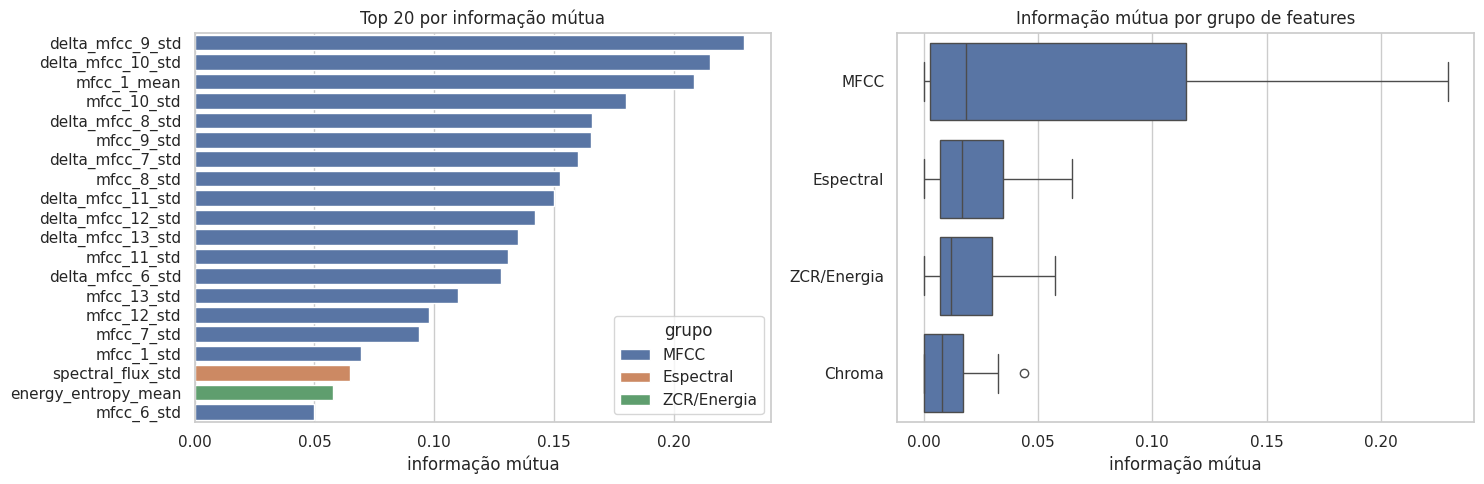

In [24]:
def group_of(c):
    base = c.removeprefix("delta_")
    if base.startswith("mfcc"): return "MFCC"
    if base.startswith("chroma"): return "Chroma"
    if base.startswith("spectral"): return "Espectral"
    return "ZCR/Energia"

rank["grupo"] = [group_of(c) for c in rank.index]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top = rank.head(20)
sns.barplot(x=top.mi, y=top.index, hue=top.grupo, dodge=False, ax=axes[0])
axes[0].set(title="Top 20 por informação mútua", xlabel="informação mútua", ylabel="")
sns.boxplot(data=rank, x="mi", y="grupo", ax=axes[1])
axes[1].set(title="Informação mútua por grupo de features", xlabel="informação mútua", ylabel="")
plt.tight_layout(); savefig("eda-ranking"); plt.show()

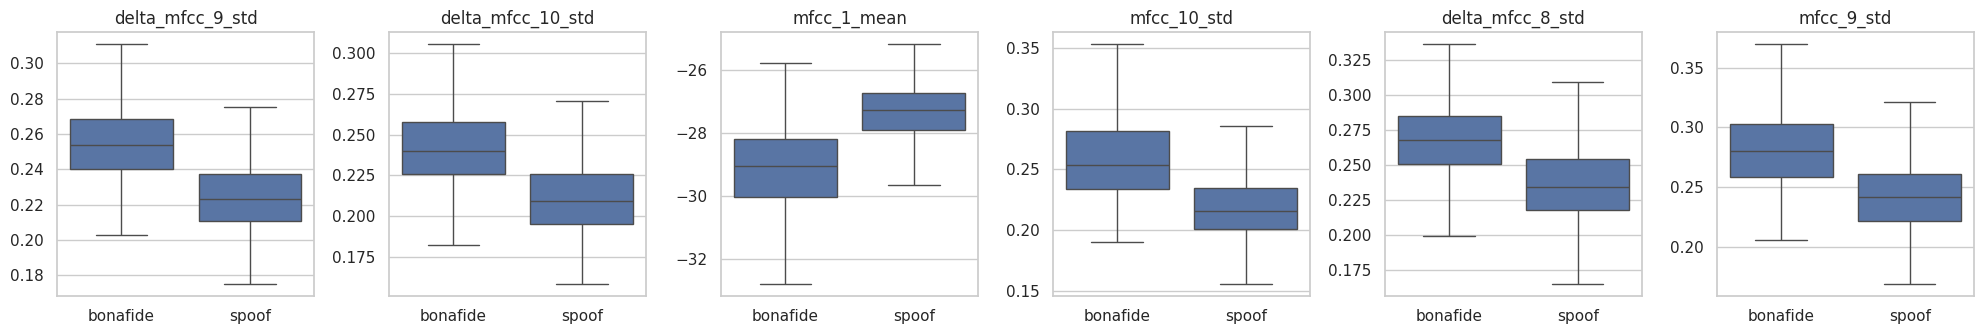

In [25]:
top6 = rank.index[:6]
fig, axes = plt.subplots(1, 6, figsize=(20, 3.5))
for ax, c in zip(axes, top6):
    sns.boxplot(data=train, x="label", y=c, ax=ax, showfliers=False)
    ax.set(title=c, xlabel="", ylabel="")
plt.tight_layout(); savefig("eda-boxplots"); plt.show()

### Projeção 2D

PCA nas 136 features padronizadas, colorida por rótulo e, para o spoof, por ataque.

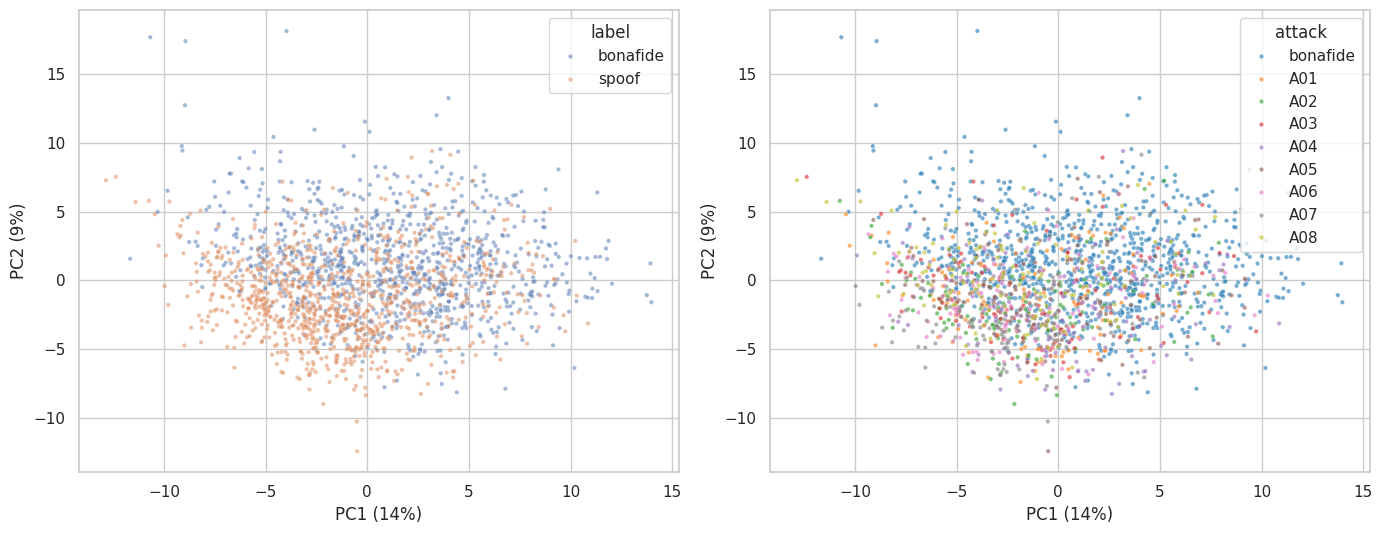

In [26]:
from sklearn.decomposition import PCA

scaler = StandardScaler().fit(X_tr)
pca = PCA(2, random_state=SEED).fit(scaler.transform(X_tr))
Z = pca.transform(scaler.transform(X_tr))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=train.label, s=10, alpha=0.5, ax=axes[0])
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=train.attack, s=10, alpha=0.6, palette="tab10", ax=axes[1])
for ax in axes:
    ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); savefig("eda-pca"); plt.show()

## 6. Classificadores

Cinco modelos do scikit-learn. Os que dependem de escala ficam num `Pipeline` com `StandardScaler`, para a normalização ser
ajustada só no fold de treino.

Métricas, com spoof como classe positiva: acurácia, F1, ROC-AUC e EER (equal error rate, o ponto em que a taxa de
falso aceite é igual à de falsa rejeição), que é a métrica padrão do ASVspoof. A EER não depende de limiar, então é a melhor
para comparar os modelos.

A validação cruzada é um `StratifiedGroupKFold` com 5 folds e o falante como grupo. Assim nenhum falante aparece no treino e no
teste do mesmo fold e o modelo não ganha pontos por reconhecer a voz.

### Ajuste do SVM

O estudo de caso usa SVM; antes de comparar, busco `C` e `gamma` do kernel RBF na mesma validação cruzada.

In [27]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm_grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.001]},
    cv=CV, scoring="roc_auc", n_jobs=-1,
).fit(X_tr, y_tr, groups=g_tr)
print(svm_grid.best_params_, f"AUC CV = {svm_grid.best_score_:.3f}")
pd.DataFrame(svm_grid.cv_results_).pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score").round(3)

{'svc__C': 100, 'svc__gamma': 0.001} AUC CV = 0.992


param_svc__gamma,0.001,0.01,scale
param_svc__C,,,
1,0.981,0.985,0.986
10,0.989,0.988,0.990
100,0.992,0.988,0.990


In [28]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

MODELS = {
    "SVM (RBF)": svm_grid.best_estimator_,
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Random Forest": RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
    "MLP": make_pipeline(StandardScaler(), MLPClassifier((128, 64), max_iter=500, early_stopping=True, random_state=SEED)),
}

def score(model, X):
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]

def eer(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    return (fpr[i] + fnr[i]) / 2

def metrics(model, X, y):
    s, p = score(model, X), model.predict(X)
    return {"acc": accuracy_score(y, p), "f1": f1_score(y, p), "auc": roc_auc_score(y, s), "eer": eer(y, s)}

def cross_validate(model, X, y, groups):
    folds, oof = [], np.zeros(len(y))
    for tr, va in CV.split(X, y, groups):
        m = clone(model).fit(X[tr], y[tr])
        folds.append(metrics(m, X[va], y[va]))
        oof[va] = m.predict(X[va])
    return pd.DataFrame(folds), oof

In [29]:
results, oof_pred, fitted = [], {}, {}
for name, model in MODELS.items():
    t = time.time()
    folds, oof_pred[name] = cross_validate(model, X_tr, y_tr, g_tr)
    fitted[name] = clone(model).fit(X_tr, y_tr)
    te = metrics(fitted[name], X_te, y_te)
    row = {"modelo": name}
    row.update({f"cv_{k}": f"{v:.3f} ± {folds[k].std():.3f}" for k, v in folds.mean().items()})
    row.update({f"teste_{k}": round(v, 3) for k, v in te.items()})
    row["cv_eer_mean"] = folds.eer.mean()
    results.append(row)
    print(f"{name}: {time.time() - t:.0f}s")

res = pd.DataFrame(results).sort_values("cv_eer_mean").drop(columns="cv_eer_mean").reset_index(drop=True)
res.to_csv(f"{BASE}/resultados-modelos.csv", index=False)
res

SVM (RBF): 1s
Regressão logística: 0s
Random Forest: 56s
HistGradientBoosting: 10s
MLP: 8s


,modelo,cv_acc,cv_f1,cv_auc,cv_eer,teste_acc,teste_f1,teste_auc,teste_eer
0,SVM (RBF),0.953 ± 0.013,0.953 ± 0.012,0.992 ± 0.003,0.046 ± 0.013,0.702,0.644,0.774,0.303
1,Regressão logística,0.944 ± 0.007,0.944 ± 0.006,0.987 ± 0.004,0.055 ± 0.016,0.685,0.615,0.735,0.320
2,MLP,0.934 ± 0.020,0.934 ± 0.019,0.981 ± 0.009,0.058 ± 0.018,0.702,0.633,0.774,0.298
3,HistGradientBoosting,0.919 ± 0.017,0.918 ± 0.019,0.980 ± 0.009,0.080 ± 0.012,0.696,0.647,0.779,0.288
4,Random Forest,0.906 ± 0.023,0.905 ± 0.023,0.973 ± 0.013,0.085 ± 0.023,0.699,0.650,0.772,0.292


As colunas `cv_*` são média ± desvio dos 5 folds no treino (ataques A01 a A08, falantes separados). As colunas `teste_*` são
do modelo treinado no treino inteiro e avaliado no dev, com os ataques A09 a A16, que ele nunca viu. A diferença entre as duas
mede o quanto o detector perde com ataques novos.

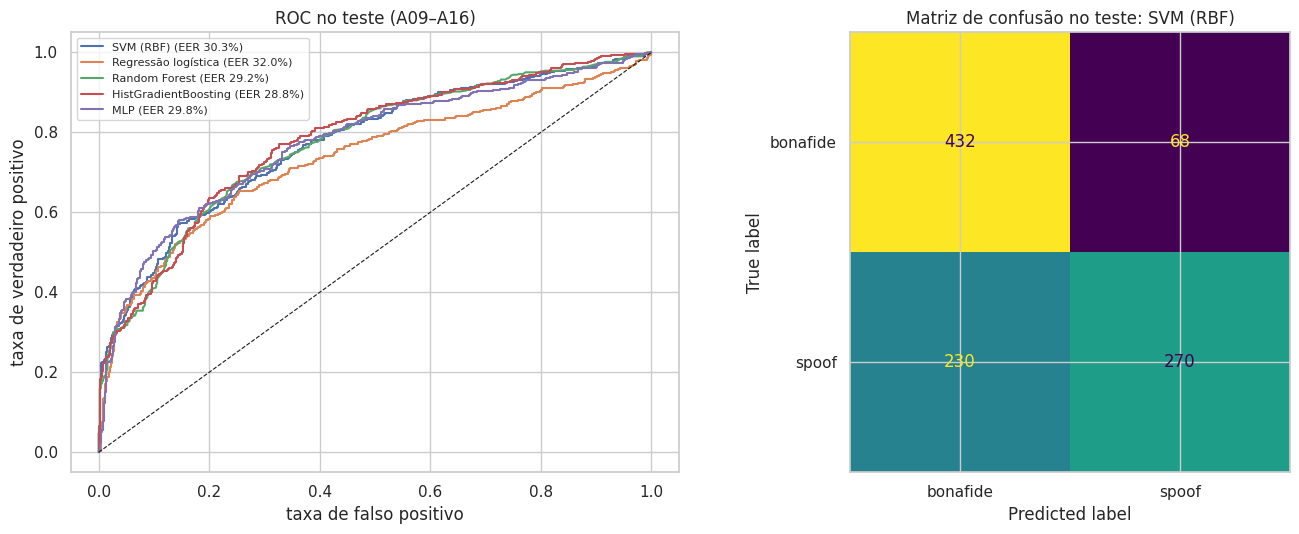

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, m in fitted.items():
    fpr, tpr, _ = roc_curve(y_te, score(m, X_te))
    axes[0].plot(fpr, tpr, label=f"{name} (EER {eer(y_te, score(m, X_te)):.1%})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="taxa de falso positivo", ylabel="taxa de verdadeiro positivo", title="ROC no teste (A09–A16)")
axes[0].legend(fontsize=8)

best = res.modelo[0]  # melhor EER na validação cruzada
ConfusionMatrixDisplay(confusion_matrix(y_te, fitted[best].predict(X_te)),
                       display_labels=["bonafide", "spoof"]).plot(ax=axes[1], colorbar=False)
axes[1].set(title=f"Matriz de confusão no teste: {best}")
plt.tight_layout(); savefig("modelos-roc-cm"); plt.show()

### Acerto por ataque

Para o melhor modelo: no treino, a taxa de detecção de cada ataque A01 a A08 nas predições fora do fold da validação cruzada;
no teste, a de cada ataque A09 a A16. Para o bonafide, a barra é a taxa de acerto (classificado como bonafide).

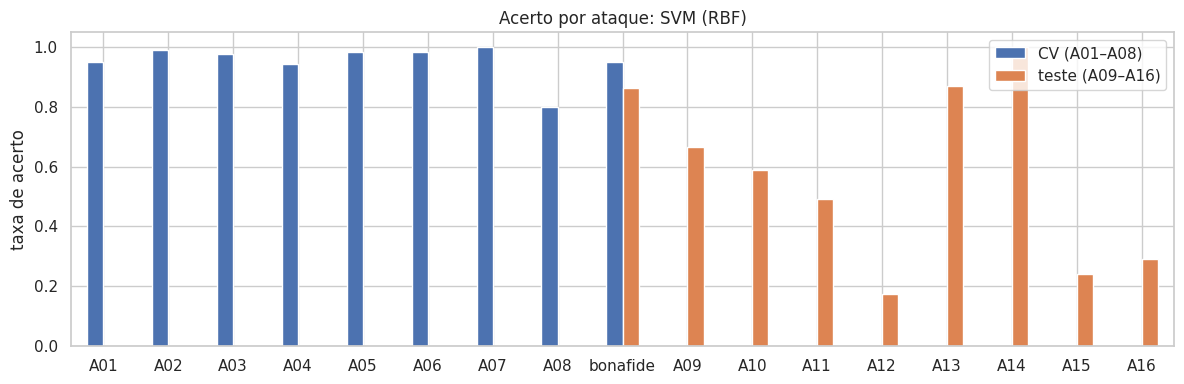

,CV (A01–A08),teste (A09–A16)
attack,,
A01,0.952,NaN
A02,0.992,NaN
A03,0.976,NaN
A04,0.944,NaN
A05,0.984,NaN
A06,0.984,NaN
A07,1.000,NaN
A08,0.800,NaN
bonafide,0.951,0.864


In [31]:
def per_attack(df, pred):
    return df.assign(ok=(pred == df.y)).groupby("attack").ok.mean()

pa = pd.concat([per_attack(train, oof_pred[best]).rename("CV (A01–A08)"),
                per_attack(test, fitted[best].predict(X_te)).rename("teste (A09–A16)")], axis=1)
ax = pa.plot.bar(figsize=(12, 4), rot=0, ylim=(0, 1.05))
ax.set(title=f"Acerto por ataque: {best}", ylabel="taxa de acerto", xlabel="")
plt.tight_layout(); savefig("modelos-por-ataque"); plt.show()
pa.round(3)

## 7. Sensibilidade às features

Ablação por grupo: treino só com o grupo e com todas as features menos ele, e comparo a EER (validação cruzada e teste) com o
conjunto completo. Os grupos seguem a divisão do pyAudioAnalysis; também comparo só médias × só desvios e com × sem deltas.
Faço isso com o SVM ajustado e com o HistGradientBoosting, que reagem de forma diferente a features irrelevantes.

In [32]:
groups = {g: [c for c in FEAT_COLS if group_of(c) == g] for g in ["ZCR/Energia", "Espectral", "MFCC", "Chroma"]}
configs = {"todas (136)": FEAT_COLS}
for g, cols in groups.items():
    configs[f"só {g}"] = cols
    configs[f"sem {g}"] = [c for c in FEAT_COLS if c not in cols]
configs["só médias"] = [c for c in FEAT_COLS if c.endswith("_mean")]
configs["só desvios"] = [c for c in FEAT_COLS if c.endswith("_std")]
configs["sem deltas"] = [c for c in FEAT_COLS if not c.startswith("delta_")]
configs["só deltas"] = [c for c in FEAT_COLS if c.startswith("delta_")]

abl = []
for model_name in ["SVM (RBF)", "HistGradientBoosting"]:
    for cfg, cols in tqdm(configs.items(), desc=model_name):
        Xa, Xb = train[cols].values, test[cols].values
        folds, _ = cross_validate(MODELS[model_name], Xa, y_tr, g_tr)
        te = metrics(clone(MODELS[model_name]).fit(Xa, y_tr), Xb, y_te)
        abl.append({"modelo": model_name, "features": cfg, "n": len(cols),
                    "cv_eer": folds.eer.mean(), "teste_eer": te["eer"]})
abl = pd.DataFrame(abl)
abl.to_csv(f"{BASE}/resultados-ablacao.csv", index=False)
abl.pivot(index=["features", "n"], columns="modelo", values=["cv_eer", "teste_eer"]).round(3)

SVM (RBF):   0%|          | 0/13 [00:00<?, ?it/s]

HistGradientBoosting:   0%|          | 0/13 [00:00<?, ?it/s]

cv_eer                      teste_eer  \
modelo              HistGradientBoosting SVM (RBF) HistGradientBoosting   
features        n                                                         
sem Chroma      84                 0.073     0.049                0.284   
sem Espectral   116                0.080     0.047                0.285   
sem MFCC        84                 0.175     0.120                0.425   
sem ZCR/Energia 124                0.074     0.046                0.288   
sem deltas      68                 0.090     0.065                0.282   
só Chroma       52                 0.268     0.204                0.391   
só Espectral    20                 0.227     0.202                0.466   
só MFCC         52                 0.073     0.058                0.277   
só ZCR/Energia  12                 0.251     0.230                0.470   
só deltas       68                 0.113     0.084                0.314   
só desvios      68                 0.089     0.047                0.335   
só médias       68                 0.145     0.127                0.371   
todas (136)     136                0.080     0.046                0.288   

                               
modelo              SVM (RBF)  
features        n              
sem Chroma      84      0.300  
sem Espectral   116     0.264  
sem MFCC        84      0.398  
sem ZCR/Energia 124     0.319  
sem deltas      68      0.313  
só Chroma       52      0.432  
só Espectral    20      0.410  
só MFCC         52      0.270  
só ZCR/Energia  12      0.447  
só deltas       68      0.347  
só desvios      68      0.297  
só médias       68      0.396  
todas (136)     136     0.303

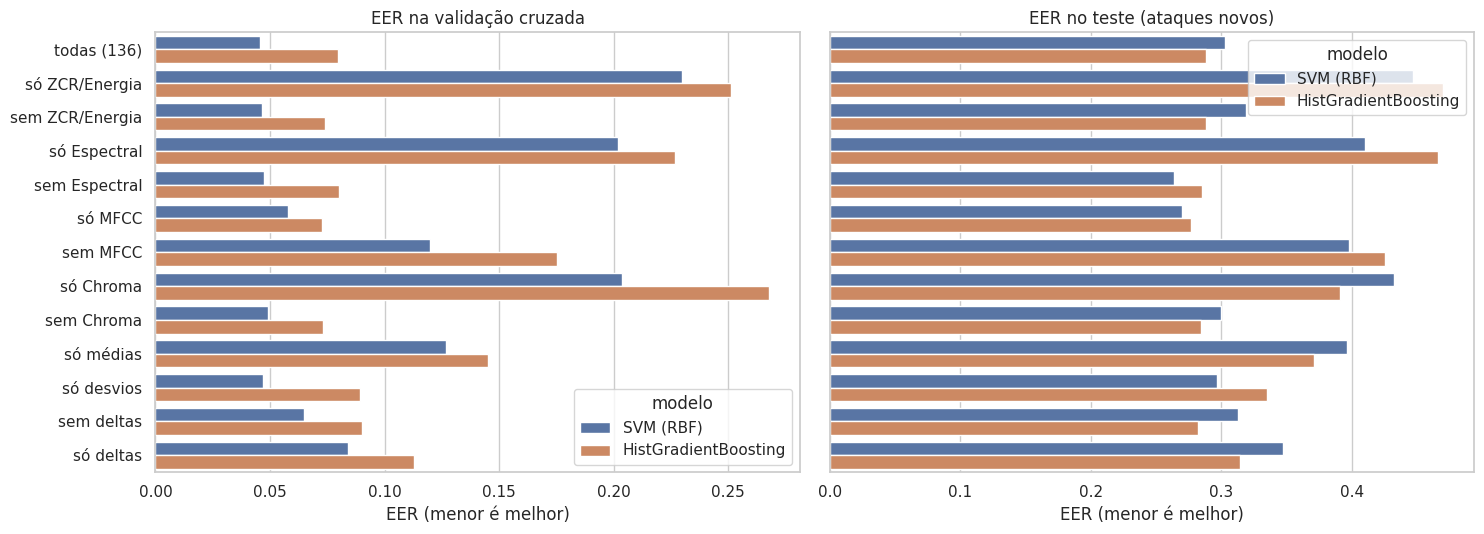

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, col, title in zip(axes, ["cv_eer", "teste_eer"], ["EER na validação cruzada", "EER no teste (ataques novos)"]):
    sns.barplot(data=abl, y="features", x=col, hue="modelo", ax=ax)
    ax.set(title=title, xlabel="EER (menor é melhor)", ylabel="")
plt.tight_layout(); savefig("sensibilidade-ablacao"); plt.show()

### Importância por permutação

Embaralho uma feature de cada vez no teste e meço quanto a AUC do HistGradientBoosting cai. Diferente da informação mútua da
EDA, isso mede o que o modelo de fato usa, e em ataques que ele não viu no treino.

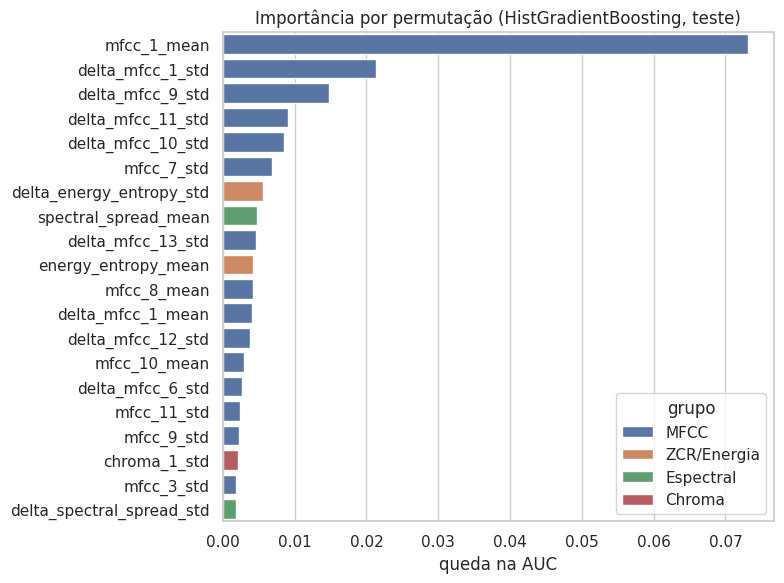

,queda_auc
grupo,
MFCC,0.1683
ZCR/Energia,0.0076
Chroma,-0.0002
Espectral,-0.0050


In [34]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(fitted["HistGradientBoosting"], X_te, y_te, scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"queda_auc": pi.importances_mean, "std": pi.importances_std}, index=FEAT_COLS)
imp["grupo"] = [group_of(c) for c in imp.index]
imp = imp.sort_values("queda_auc", ascending=False)

top = imp.head(20)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.queda_auc, y=top.index, hue=top.grupo, dodge=False)
plt.title("Importância por permutação (HistGradientBoosting, teste)"); plt.xlabel("queda na AUC"); plt.ylabel("")
plt.tight_layout(); savefig("sensibilidade-permutacao"); plt.show()
imp.groupby("grupo").queda_auc.sum().sort_values(ascending=False).round(4)

## 8. Amostras maiores: curva de aprendizado

Treino com 250, 500, 1000 e 2500 amostras por classe (sempre balanceado e estratificado por ataque, tirado do pool de treino)
e avalio na validação cruzada e no mesmo teste.

250 ok
500 ok
1000 ok
2500 ok


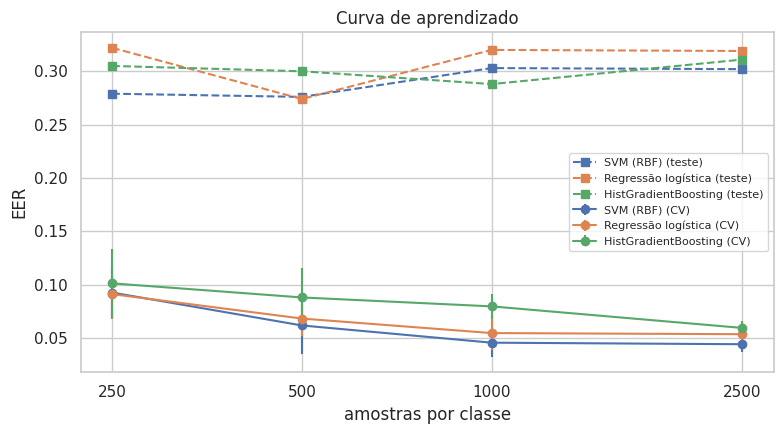

cv_eer                                \
modelo       HistGradientBoosting Regressão logística SVM (RBF)   
n_por_classe                                                      
250                         0.101               0.091     0.093   
500                         0.088               0.068     0.062   
1000                        0.080               0.055     0.046   
2500                        0.060               0.054     0.044   

                        teste_eer                                
modelo       HistGradientBoosting Regressão logística SVM (RBF)  
n_por_classe                                                     
250                         0.305               0.322     0.279  
500                         0.300               0.274     0.276  
1000                        0.288               0.320     0.303  
2500                        0.311               0.319     0.302

In [35]:
SIZES = [250, 500, 1000, N_POOL]
LC_MODELS = ["SVM (RBF)", "Regressão logística", "HistGradientBoosting"]

lc = []
for n in SIZES:
    sub = sample_balanced(pool, n).reset_index(drop=True)
    Xs, ys, gs = sub[FEAT_COLS].values, sub.y.values, sub.speaker.values
    for name in LC_MODELS:
        folds, _ = cross_validate(MODELS[name], Xs, ys, gs)
        te = metrics(clone(MODELS[name]).fit(Xs, ys), X_te, y_te)
        lc.append({"n_por_classe": n, "modelo": name, "cv_eer": folds.eer.mean(), "cv_eer_std": folds.eer.std(),
                   "teste_eer": te["eer"], "teste_acc": te["acc"]})
    print(n, "ok")
lc = pd.DataFrame(lc)
lc.to_csv(f"{BASE}/resultados-curva.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, name in enumerate(LC_MODELS):
    d = lc[lc.modelo == name]
    ax.errorbar(d.n_por_classe, d.cv_eer, yerr=d.cv_eer_std, marker="o", color=f"C{i}", label=f"{name} (CV)")
    ax.plot(d.n_por_classe, d.teste_eer, marker="s", ls="--", color=f"C{i}", label=f"{name} (teste)")
ax.set(xscale="log", xticks=SIZES, xticklabels=SIZES, xlabel="amostras por classe", ylabel="EER", title="Curva de aprendizado")
ax.legend(fontsize=8)
plt.tight_layout(); savefig("curva-aprendizado"); plt.show()
lc.pivot(index="n_por_classe", columns="modelo", values=["cv_eer", "teste_eer"]).round(3)

## 9. Resumo

Tabelas para o README. As figuras estão em `figs/` na pasta do Drive.

In [36]:
print(res.to_markdown(index=False))
print()
print(abl.pivot(index="features", columns="modelo", values="teste_eer").round(3).to_markdown())
print()
print(lc.pivot(index="n_por_classe", columns="modelo", values="teste_eer").round(3).to_markdown())

| modelo               | cv_acc        | cv_f1         | cv_auc        | cv_eer        |   teste_acc |   teste_f1 |   teste_auc |   teste_eer |
|:---------------------|:--------------|:--------------|:--------------|:--------------|------------:|-----------:|------------:|------------:|
| SVM (RBF)            | 0.953 ± 0.013 | 0.953 ± 0.012 | 0.992 ± 0.003 | 0.046 ± 0.013 |       0.702 |      0.644 |       0.774 |       0.303 |
| Regressão logística  | 0.944 ± 0.007 | 0.944 ± 0.006 | 0.987 ± 0.004 | 0.055 ± 0.016 |       0.685 |      0.615 |       0.735 |       0.32  |
| MLP                  | 0.934 ± 0.020 | 0.934 ± 0.019 | 0.981 ± 0.009 | 0.058 ± 0.018 |       0.702 |      0.633 |       0.774 |       0.298 |
| HistGradientBoosting | 0.919 ± 0.017 | 0.918 ± 0.019 | 0.980 ± 0.009 | 0.080 ± 0.012 |       0.696 |      0.647 |       0.779 |       0.288 |
| Random Forest        | 0.906 ± 0.023 | 0.905 ± 0.023 | 0.973 ± 0.013 | 0.085 ± 0.023 |       0.699 |      0.65  |       0.772 |       

## Referências

- Wang, X. et al. *ASVspoof 5: Crowdsourced Speech Data, Deepfakes, and Adversarial Attacks at Scale*. arXiv:2408.08739, 2024.
- Giannakopoulos, T. *pyAudioAnalysis: An Open-Source Python Library for Audio Signal Analysis*. PLoS ONE 10(12), 2015.
- Almeida, F. V.; Hayashi, V. T. *Identificação de Áudio Vocaloid com Support Vector Machines: um Estudo de Caso da Hatsune Miku*.
  SBCM 2021, p. 217-220. DOI: 10.5753/sbcm.2021.19451.
- Müller, N. M. et al. *Speech is Silver, Silence is Golden: What do ASVspoof-trained Models Really Learn?* ASVspoof 2021 Workshop.
- Pedregosa, F. et al. *Scikit-learn: Machine Learning in Python*. JMLR 12, 2011.